# 1. Adaptive sampling: the basics

This tutorial needs no EnergyPlus: a Python function plays the simulator, so every step runs in seconds and you
can see what adaptive sampling does. The response has a **narrow feature** (a bump) on top of a smooth trend, the
situation where adaptive sampling pays off.

We will

1. describe a problem with two parameters;
2. build a surrogate from a fixed Latin-hypercube design (the baseline);
3. build one with the adaptive sampler, using the same number of training simulations;
4. compare them.

In [1]:
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)

## The problem

A {class}`~bdopt.Parameter` couples *where* a value goes in the model (a selector) with *which values* are
allowed. Here there is no model file, so the selector does nothing (`GenericSelector`), and a
{class}`~bdopt.FunctionEvaluator` computes the response.

In [2]:
from bdopt import FunctionEvaluator, GenericSelector, Parameter, Problem, RangeParameter

params = [
    Parameter(GenericSelector(lambda idf, value: None), RangeParameter(0, 1), name=name)
    for name in ("x1", "x2")
]
problem = Problem(params, ["f"])

def simulator(row):
    """A smooth trend plus a narrow bump around (0.7, 0.3)."""
    bump = np.exp(-(((row["x1"] - 0.7) ** 2 + (row["x2"] - 0.3) ** 2) / 0.012))
    return [0.3 * row["x1"] + bump]

evaluator = FunctionEvaluator(problem, simulator)
problem

Problem(2 parameters, objectives=['f'])

## Baseline: a fixed Latin-hypercube design

{func}`bdopt.sampling.lhs` returns a table of designs; `evaluate` returns the objectives.

In [3]:
from bdopt import sampling
from bdopt.surrogate import GPSurrogate

N = 50
lhs_designs = sampling.lhs(problem, N, seed=3)
lhs_data = evaluator.evaluate(lhs_designs, keep_input=True)       # parameters + objective
lhs_data.head()

,x1,x2,f
0,0.1458,0.3157,0.0437
1,0.5615,0.3877,0.2751
2,0.7940,0.4846,0.2661
3,0.2540,0.5124,0.0762
4,0.9247,0.6743,0.2774


To compare fairly we need independent points the surrogates have never seen:

In [4]:
reference = sampling.lhs(problem, 2000, seed=99)
truth = evaluator.evaluate(reference)["f"].to_numpy()

def error(surrogate):
    """RMSE on the reference points, divided by the standard deviation of the response."""
    prediction = surrogate.predict(reference)["f"].to_numpy()
    return float(np.sqrt(np.mean((prediction - truth) ** 2)) / truth.std())

lhs_surrogate = GPSurrogate().fit(lhs_data, problem)
print(f"Latin hypercube, {N} points: relative error {error(lhs_surrogate):.3f}")

Latin hypercube, 50 points: relative error 0.223


## Adaptive sampling

{class}`~bdopt.adaptive.AdaptiveSampler` starts from a small Latin hypercube (`n_initial`), holds out `n_test`
simulations to measure the surrogate's error, and then adds simulations where the surrogate needs them. Here we
ask for exactly the same number of training points as the baseline: 12 initial + 38 adaptive = 50
(`tol=0` disables early stopping).

In [5]:
from bdopt.adaptive import AdaptiveSampler

sampler = AdaptiveSampler(problem, evaluator, method="flola_voronoi", seed=3)
result = sampler.run(n_initial=12, n_test=10, max_iter=38, tol=0, verbose=False)
print(result)
result.history[["iteration", "n_train", "n_evaluations", "scaled_rmse"]].tail()

AdaptiveResult(50 train + 10 test points, scaled_rmse=0.2182, stop='max_iter')


,iteration,n_train,n_evaluations,scaled_rmse
34,34,46,56,0.2305
35,35,47,57,0.2259
36,36,48,58,0.2230
37,37,49,59,0.2180
38,38,50,60,0.2182


In [6]:
adaptive_surrogate = GPSurrogate().fit(result.data, problem)
print(f"Adaptive, {len(result.data)} points:      relative error {error(adaptive_surrogate):.3f}")

Adaptive, 50 points:      relative error 0.164


## Where did the simulations go?

Grey contours show the true response. The Latin hypercube spreads points evenly; the adaptive sampler starts the
same way (dark points) and then places new simulations (green, yellow) on and around the bump, where the
response is nonlinear.

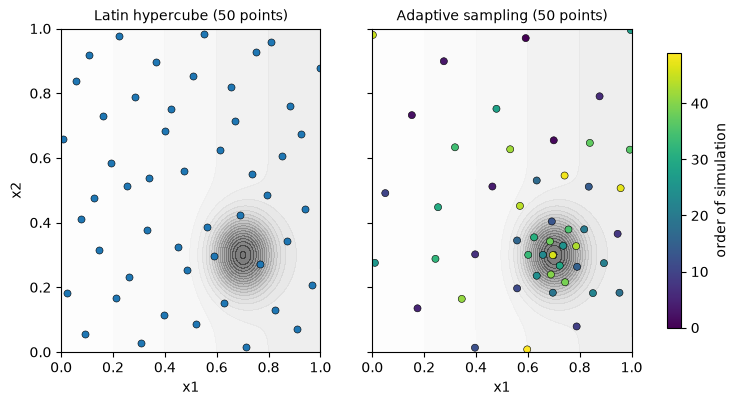

In [7]:
gx, gy = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
surface = 0.3 * gx + np.exp(-(((gx - 0.7) ** 2 + (gy - 0.3) ** 2) / 0.012))

fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.2), sharey=True)
for ax, points, title in ((axes[0], lhs_data, "Latin hypercube"), (axes[1], result.data, "Adaptive sampling")):
    ax.contourf(gx, gy, surface, levels=20, cmap="Greys", alpha=0.55)
    colour = np.arange(len(points)) if ax is axes[1] else "tab:blue"
    sc = ax.scatter(points["x1"], points["x2"], c=colour, cmap="viridis", s=26, edgecolor="k", linewidth=0.4)
    ax.set_title(f"{title} ({len(points)} points)", fontsize=10)
    ax.set_xlabel("x1")
axes[0].set_ylabel("x2")
fig.colorbar(sc, ax=axes, shrink=0.85, label="order of simulation")
plt.show()

## Convergence

`history` has one row per iteration. `scaled_rmse` is the surrogate's error on the held-out simulations, in units
of the standard deviation of the response. With a real budget you would set `tol` (for example `0.05`) and let
the loop stop by itself, learning how many simulations were enough.

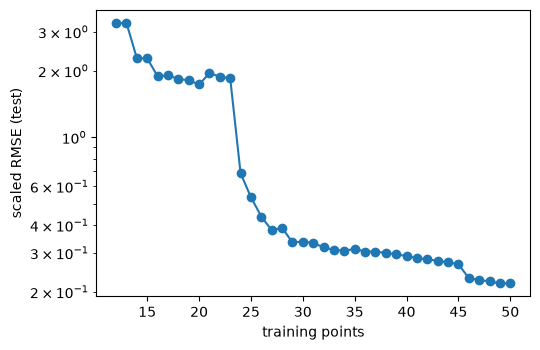

In [8]:
from bdopt import viz

fig = viz.convergence(result.history)
plt.show()

## What to take away

* Both surrogates used 50 training simulations; the numbers above are what each achieved on 2000 unseen points.
* The gain depends on the response. It is large for a localised feature like this one; for a smooth response a
  Latin hypercube is as good, and the adaptive loop is then mainly a way to *know* when you have simulated
  enough. The measured comparison is in {doc}`../guide/adaptive-sampling`.
* In a real study replace the `FunctionEvaluator` with an {class}`~bdopt.EnergyPlusEvaluator` and the
  `GenericSelector` with `FieldSelector` objects: tutorial 2 does that.